In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [2]:
# Direktori dataset
data_dir = r"D:\Document\Kuliah\Semster5\AI\TUBESAI\image_machine_learning"
train_dir = f"{data_dir}\\train"
test_dir = f"{data_dir}\\testing"


In [3]:
# Parameter utama
image_size = (150, 150)  # Ukuran gambar
batch_size = 32  # Jumlah gambar per batch

In [4]:
# Data augmentation untuk training
train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)


In [5]:
# Rescale untuk data testing
test_datagen = ImageDataGenerator(rescale=1.0/255.0)

In [6]:
# Load data training dan testing
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=image_size,
    batch_size=batch_size,
    class_mode='categorical'
)

Found 4800 images belonging to 4 classes.
Found 1200 images belonging to 4 classes.


In [7]:
# Membangun model CNN
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(image_size[0], image_size[1], 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(4, activation='softmax')  # 4 kelas: ManusiaAI, ManusiaReal, PemandanganAI, PemandanganReal
])

C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# Kompilasi model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [9]:
# Menampilkan arsitektur model
model.summary()

# Training model
epochs = 20
history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=test_generator
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,868 (18.42 MB)

 Trainable params: 4,828,868 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
 13/150 ━━━━━━━━━━━━━━━━━━━━ 3:05 1s/step - accuracy: 0.3065 - loss: 1.5420

C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\PIL\Image.py:3406: DecompressionBombWarning: Image size (108000000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4993 - loss: 1.1478

C:\Users\Lenovo\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


150/150 ━━━━━━━━━━━━━━━━━━━━ 241s 2s/step - accuracy: 0.5001 - loss: 1.1462 - val_accuracy: 0.6583 - val_loss: 0.7674
Epoch 2/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 261s 2s/step - accuracy: 0.7222 - loss: 0.6722 - val_accuracy: 0.6508 - val_loss: 0.9199
Epoch 3/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 287s 2s/step - accuracy: 0.7839 - loss: 0.5587 - val_accuracy: 0.7642 - val_loss: 0.5458
Epoch 4/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 254s 2s/step - accuracy: 0.8156 - loss: 0.4747 - val_accuracy: 0.7350 - val_loss: 0.7019
Epoch 5/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 241s 2s/step - accuracy: 0.8087 - loss: 0.5002 - val_accuracy: 0.7508 - val_loss: 0.6632
Epoch 6/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 236s 2s/step - accuracy: 0.8361 - loss: 0.4230 - val_accuracy: 0.8542 - val_loss: 0.4210
Epoch 7/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 238s 2s/step - accuracy: 0.8641 - loss: 0.3808 - val_accuracy: 0.8150 - val_loss: 0.5818
Epoch 8/20
150/150 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.8564 - loss: 0.3702 - val_accuracy: 0.859

In [10]:
# Menyimpan model
model.save("image_classification_cnn.h5")

In [11]:
# Evaluasi model pada data testing
loss, accuracy = model.evaluate(test_generator)
print(f"Testing Loss: {loss}")
print(f"Testing Accuracy: {accuracy}")

38/38 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.8349 - loss: 0.6782
Testing Loss: 0.5851420760154724
Testing Accuracy: 0.8508333563804626


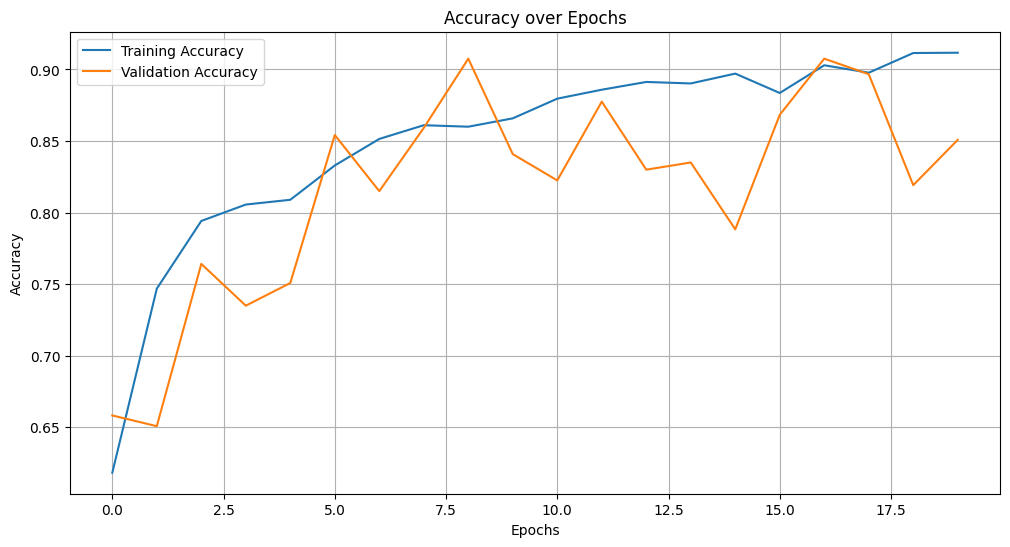

In [12]:
# Plot Akurasi
plt.figure(figsize=(12, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

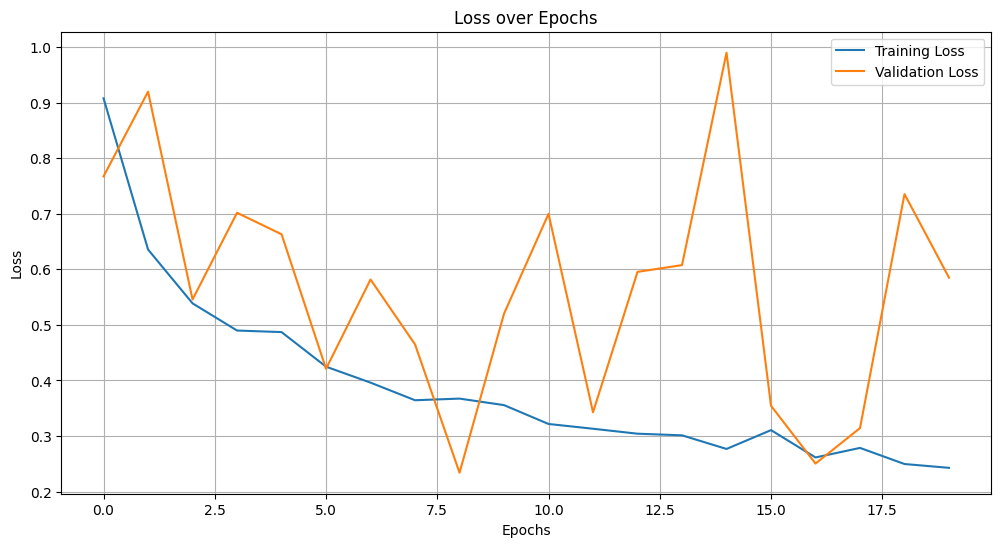

In [13]:
# Plot Loss
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# Menampilkan beberapa gambar dari testing dataset dengan prediksi
class_labels = list(test_generator.class_indices.keys())  # Nama kelas

In [15]:
def display_predictions(test_dir, model, class_labels, image_size, num_images=5):
    for class_name in os.listdir(test_dir):
        class_folder = os.path.join(test_dir, class_name)
        if not os.path.isdir(class_folder):
            continue
        print(f"\nClass: {class_name}")
        images = os.listdir(class_folder)
        selected_images = np.random.choice(images, num_images, replace=False)
        
        for img_name in selected_images:
            img_path = os.path.join(class_folder, img_name)
            img = load_img(img_path, target_size=image_size)
            img_array = img_to_array(img) / 255.0  # Rescale seperti data generator
            img_array = np.expand_dims(img_array, axis=0)  # Tambahkan dimensi batch
            
            prediction = model.predict(img_array)
            predicted_class = class_labels[np.argmax(prediction)]
            confidence = np.max(prediction)
            
            plt.imshow(img)
            plt.title(f"Predicted: {predicted_class} ({confidence:.2f})\nActual: {class_name}")
            plt.axis('off')
            plt.show()


Class: ManusiaAI
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


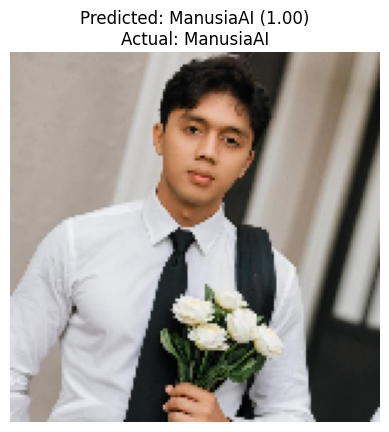

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


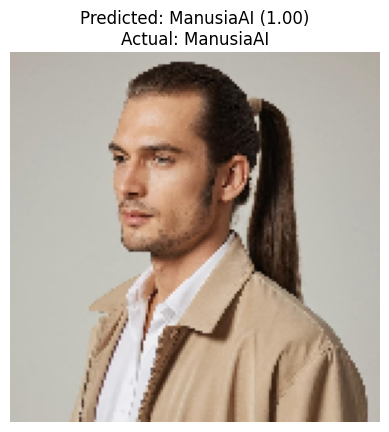

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


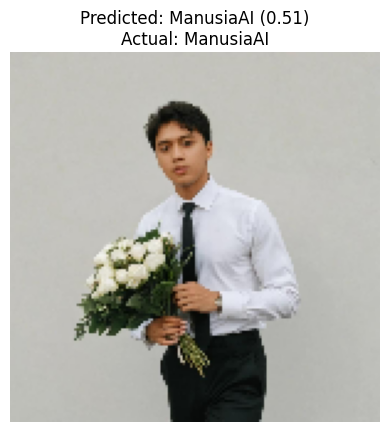

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


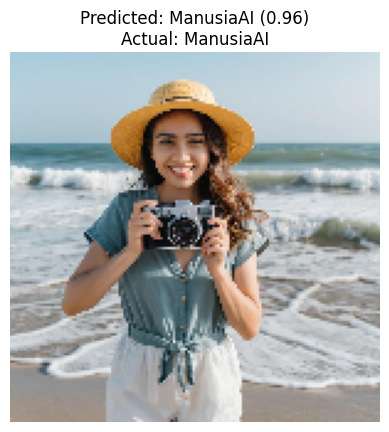

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


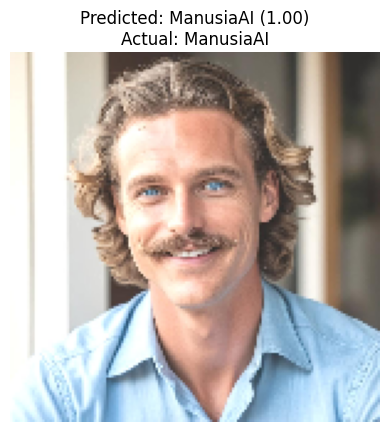


Class: ManusiaReal
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


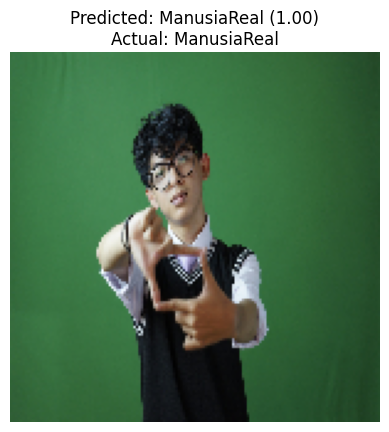

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


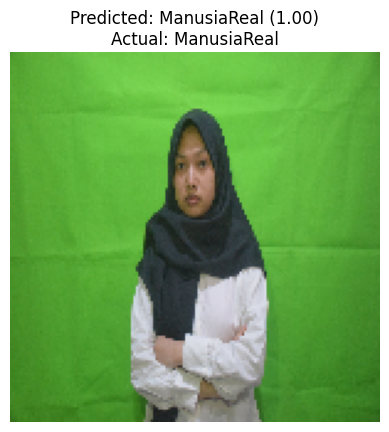

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


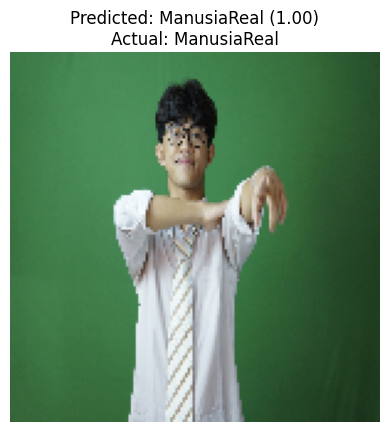

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


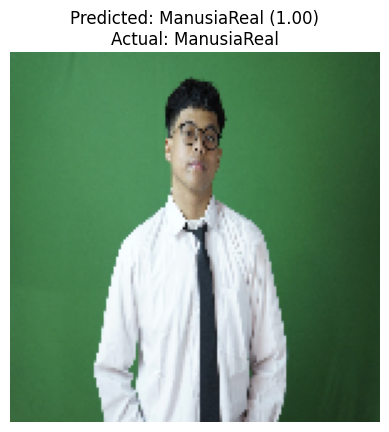

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


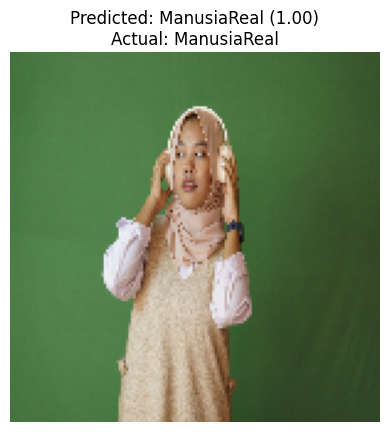


Class: PemandanganAI
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


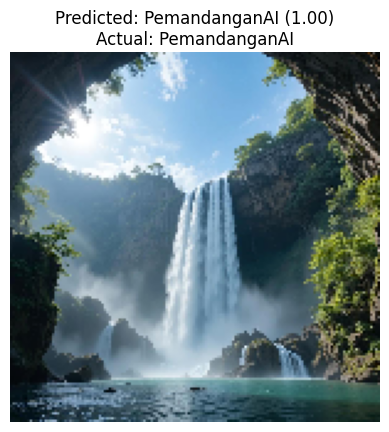

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


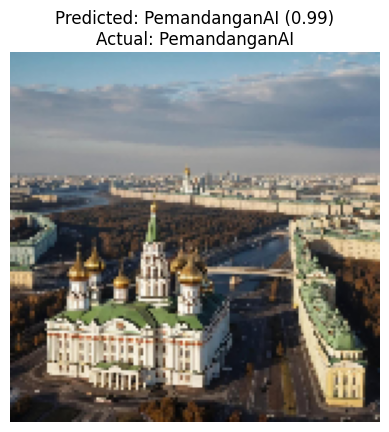

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


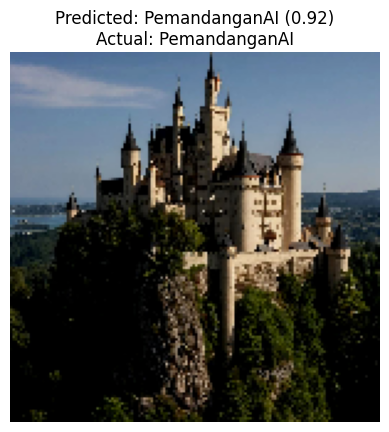

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


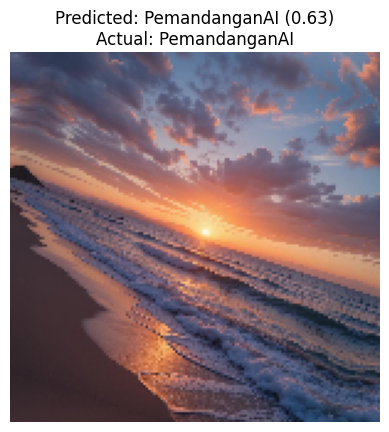

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


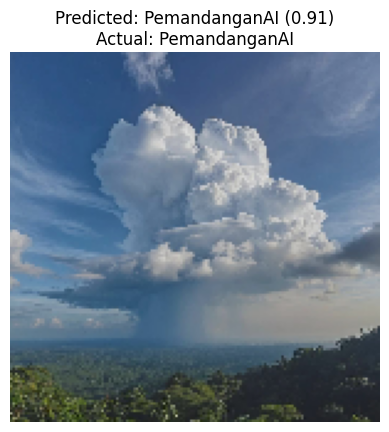


Class: PemandanganReal
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


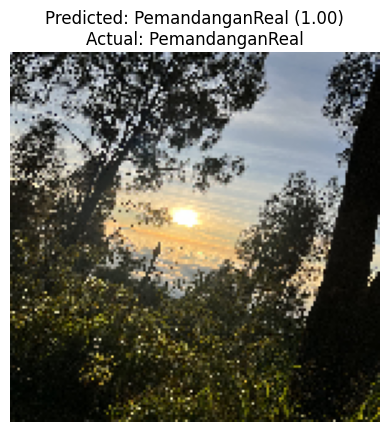

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


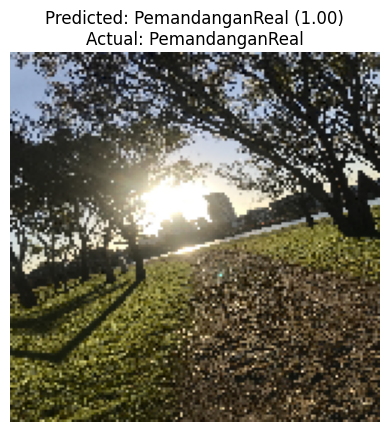

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


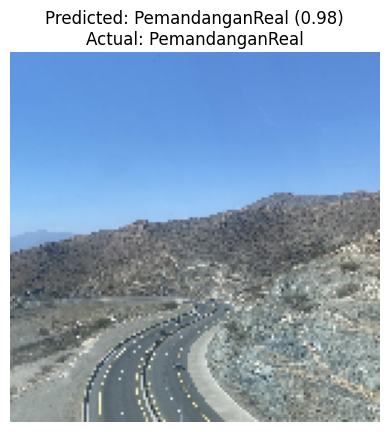

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


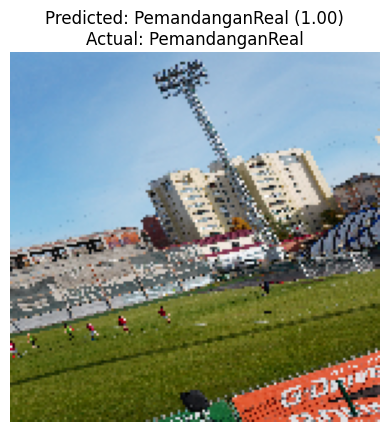

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


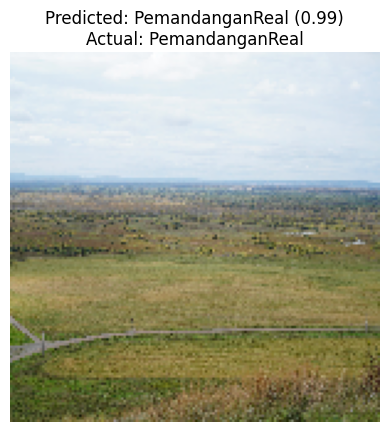

In [16]:
# Menampilkan prediksi
display_predictions(test_dir, model, class_labels, image_size)